# Ollama VLM Benchmark

We test how well an open-weights vision-language model (VLM) running **locally through Ollama** can classify our brain MRI scans into the four classes (glioma, meningioma, notumor, pituitary) **without any training**.

A VLM is a language model with an image front end. A vision encoder turns the picture into a grid of embeddings, a small projector maps them into the language model's token space, and the language model then reads those image tokens next to our text prompt and writes an answer. We never update any weights here, we only change what we show the model.

We try two setups:

1. **Zero-shot**: the model only gets the image and a description of the task.
2. **Few-shot**: the model also gets a few labelled example images taken from our **training set**, so it can see what each class looks like in this dataset before it classifies a test image.

We use the same splits and metrics as the other notebooks, so the results can be compared directly with Naive_Benchmark.ipynb (macro F1 ≈ 0.25) and Decision_Tree_Baseline.ipynb. Because the model runs on our own GPU, there is no API key, no rate limit and no cost per image.

## Setup

1. Install [Ollama](https://ollama.com) and make sure it is running. The desktop app starts the server in the background, otherwise run ollama serve in a terminal.
2. Download a vision model once (about 3 GB): ollama pull qwen2.5vl:3b. If your GPU has 8 GB of memory or more, you can also try the larger qwen2.5vl:7b (about 6 GB). Run ollama list to see which models you have.
3. Install the Python packages. ollama (the Python client) is now listed in requirements.txt, so re-run this if your virtual environment is older:

bash
pip install -r requirements.txt


No API key is needed. If Ollama runs on a different machine, set the OLLAMA_HOST environment variable (for example http://192.168.1.20:11434) before starting Jupyter.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!apt-get install -y zstd
!pip install -q ollama
!curl -fsSL https://ollama.com/install.sh | sh

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  zstd
0 upgraded, 1 newly installed, 0 to remove and 33 not upgraded.
Need to get 644 kB of archives.
After this operation, 1,845 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble-updates/main amd64 zstd amd64 1.5.5+dfsg2-2build1.1 [644 kB]
Fetched 644 kB in 1s (1,107 kB/s)
Selecting previously unselected package zstd.
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../zstd_1.5.5+dfsg2-2build1.1_amd64.deb ...
Unpacking zstd (1.5.5+dfsg2-2build1.1) ...
Setting up zstd (1.5.5+dfsg2-2build1.1) ...
Processing triggers for man-db (2.12.0-4build2) ...
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video gr

In [3]:
!nohup ollama serve > ollama.log 2>&1 &
!sleep 5
!ollama pull qwen2.5vl:7b

In [4]:
import os
import re
import csv
import enum
import time
from pathlib import Path

import httpx
import ollama
import pandas as pd
import matplotlib.pyplot as plt
from pydantic import BaseModel
from sklearn.metrics import classification_report, accuracy_score, f1_score, ConfusionMatrixDisplay

In [5]:
!nvidia-smi
!ollama ps
!ollama list
!tail -n 30 ollama.log

Sat Oct 31 06:43:58 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Configuration

All the settings for the experiment are in one place:

- MODEL: which Ollama model to use. It must be a **vision** model that you pulled with ollama pull (text-only models such as qwen3:8b cannot see images). The default, qwen2.5vl:3b, is small enough for a laptop GPU with about 4 GB of memory. A 7B model such as qwen2.5vl:7b needs very roughly 6-8 GB, and if it does not fit, Ollama runs part of it on the CPU, which is much slower. Compare models by changing this one line and re-running.
- SAMPLE_PER_CLASS: how many test images per class to classify. None runs the **full test set** (1,584 images). We first ran a stratified **pilot sample** of 50 per class (200 images) to check the setup and estimate run time; set it back to 50 to reproduce only the pilot.
- PILOT_PER_CLASS: the size of that pilot sample. The full-test-set results are compared against it at the end of the notebook, to see whether the 200-image results were representative.
- FEW_SHOT_PER_CLASS: how many labelled training images per class to show the model in the few-shot setup.
- SEED: makes the sampling reproducible (the pilot sample is always the same 200 images) and also seeds the model's own sampling.
- NUM_CTX: the context window in tokens, i.e. the longest prompt the model accepts. With qwen2.5vl:3b, Ollama turns **every image into about 1,050 tokens regardless of its size**, so the few-shot prompt (8 examples + the test image) is about 9,600 tokens. If the prompt is longer than NUM_CTX, Ollama refuses the request with exceeds the available context size. Rule of thumb: NUM_CTX ≥ 1,100 × (4 × FEW_SHOT_PER_CLASS + 1) + 500, so 12288 for 2 examples per class, 8192 for 1.

**Where results are saved:** each run has its own folder inside data/vlm_results/. The full test set goes to Full Test set/, and a sample goes to a folder named after its size (the pilot's results are in 200 Test Images/). The full run therefore classifies all 1,584 images itself, including the 200 pilot images, which also lets us check that the model gives the same answers when run twice.

**Run time:** the 8 few-shot example images are identical in every request, so Ollama reuses the work it already did on them and only processes the new test image. That is why few-shot is not 9× slower. On a 4 GB laptop GPU the pilot took about 3 s per image zero-shot and 4.4 s few-shot, so the full test set takes roughly 80 + 115 minutes (about 3 hours 15 minutes in total). It can be interrupted and resumed, see "Classifying the test set" below.

**Checking that the model fits on your GPU:** after the sanity check below has run, type ollama ps in a terminal. 100% GPU in the PROCESSOR column means everything fits. Something like 55%/45% CPU/GPU means part of the model runs on the CPU. On a 4 GB GPU that happens even with the 3B model, but it still runs at the speeds above. A larger NUM_CTX uses a bit more memory.

In [6]:
MODEL = "qwen2.5vl:7b"
SAMPLE_PER_CLASS = None     # None = full test set (1,584 images); 50 = the 200-image pilot sample
PILOT_PER_CLASS = 50        # size of the pilot sample that the full run is compared against
FEW_SHOT_PER_CLASS = 2
SEED = 0
NUM_CTX = 12288             # few-shot prompt is ~9,600 tokens (each image ~1,050), see above

CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]
DATA_DIR = Path("/content/drive/MyDrive/Colab Notebooks")

# Each run gets its own folder, kept apart from data/processed (the classical models' .npz arrays)
RESULTS_ROOT = DATA_DIR / "vlm_results"
FULL_RESULTS_DIR = RESULTS_ROOT / "Full Test set"

def sample_results_dir(per_class):
    return RESULTS_ROOT / f"{per_class * len(CLASSES)} Test Images"     # 50 per class -> "200 Test Images"

RESULTS_DIR = FULL_RESULTS_DIR if SAMPLE_PER_CLASS is None else sample_results_dir(SAMPLE_PER_CLASS)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Talks to http://localhost:11434 unless the OLLAMA_HOST environment variable says otherwise.
# The long timeout is for the first request, which has to load the model into GPU memory.
client = ollama.Client(timeout=600)

## Check that Ollama is running

Before doing anything else, we make sure the server answers and that the model has been pulled, so a missing model gives one clear message instead of hundreds of failed calls.

In [7]:
def check_ollama():
    try:
        installed = [m.model for m in client.list().models]
    except Exception as e:
        raise RuntimeError(
            "Cannot reach the Ollama server. Start the Ollama app (or run ollama serve) and try again."
        ) from e
    if MODEL not in installed and f"{MODEL}:latest" not in installed:
        raise RuntimeError(f"Model '{MODEL}' is not installed. Run ollama pull {MODEL}. Installed models: {installed}")
    print(f"Ollama is running and '{MODEL}' is installed.")

check_ollama()

Ollama is running and 'qwen2.5vl:7b' is installed.


## Load data

We use the same train.csv / test.csv splits produced by Preprocessing_Data.ipynb. The model receives the **original JPEG files**, not the preprocessed .npz arrays, since that is the input format a VLM expects. Ollama then resizes each image to the model's own input size, so the VLM sees a different (colour, higher-resolution) version of each scan than the classical models, which see 224x224 or 64x64 grayscale arrays. This is worth stating when we compare them.

The CSV paths were saved with Windows backslashes, so we convert them to forward slashes so they also work on macOS/Linux.

We also rebuild the 200-image **pilot sample** (pilot_df). Because it uses the same SEED, these are exactly the images from the first run, so we can compare against them at the end.

In [8]:
def load_csv(name):
    df = pd.read_csv(DATA_DIR / f"{name}.csv")
    df["Path"] = df["Path"].str.replace("\\", "/", regex=False)
    df["Path"] = df["Path"].str.replace("../data/", f"{DATA_DIR}/", regex=False)
    return df

def stratified_sample(df, per_class):
    return df.groupby("Labels").sample(n=per_class, random_state=SEED).reset_index(drop=True)

train_df = load_csv("train")
full_test_df = load_csv("test")
pilot_df = stratified_sample(full_test_df, PILOT_PER_CLASS)

test_df = full_test_df if SAMPLE_PER_CLASS is None else stratified_sample(full_test_df, SAMPLE_PER_CLASS)

print(f"train: {len(train_df)} images, test (to classify): {len(test_df)} images, pilot sample: {len(pilot_df)} images")
print(test_df["Labels"].value_counts())

train: 4728 images, test (to classify): 1584 images, pilot sample: 200 images
Labels
pituitary     400
notumor       400
meningioma    398
glioma        386
Name: count, dtype: int64


## Structured output

Free text answers like *"This looks like a pituitary adenoma"* would need messy string parsing. Instead we pass a **JSON schema** to Ollama: it constrains the model's output so the reply is always JSON whose label field is one of our four class names. We then parse it into a Python object.

One consequence worth remembering: the model is forced to pick one of the four classes, it cannot answer "unsure".

In [9]:
class TumourClass(str, enum.Enum):
    glioma = "glioma"
    meningioma = "meningioma"
    notumor = "notumor"
    pituitary = "pituitary"

class Prediction(BaseModel):
    label: TumourClass

RESPONSE_SCHEMA = Prediction.model_json_schema()

## Prompt

The prompt explains the task and describes each class in plain radiological terms, so the model knows exactly what the label names mean (e.g. that notumor is a healthy scan). It is sent as the system message. Keep it fixed when comparing different models, so differences in the results come from the model and not from the wording.

In [10]:
PROMPT = '''You are an expert neuroradiologist. You will be shown a brain MRI slice.
Classify it into exactly one of these classes:

- glioma: an infiltrative tumour arising from glial cells within the brain tissue, often with irregular borders and surrounding oedema.
- meningioma: a well-defined, extra-axial tumour arising from the meninges, usually attached to the skull or dura.
- pituitary: a tumour in the sella turcica region at the base of the brain, below the optic chiasm.
- notumor: a healthy brain with no visible tumour.

Answer with the single most likely class.'''

## Few-shot examples from the training set

For the few-shot setup we randomly pick FEW_SHOT_PER_CLASS labelled images per class from the **training set** (never the test set, so there is no leakage). With the same SEED, every model and every teammate gets the same example images.

Ollama is a chat API, so each example becomes a short conversation turn: a user message with the example image, then an assistant message with the correct answer in the same JSON format we ask for. That is the format chat models were trained on, and it also works for models that only accept one image per message. The examples are **shuffled**, otherwise the last example would always be the same class and could nudge the model towards it.

They are sent with every request, before the image to classify.

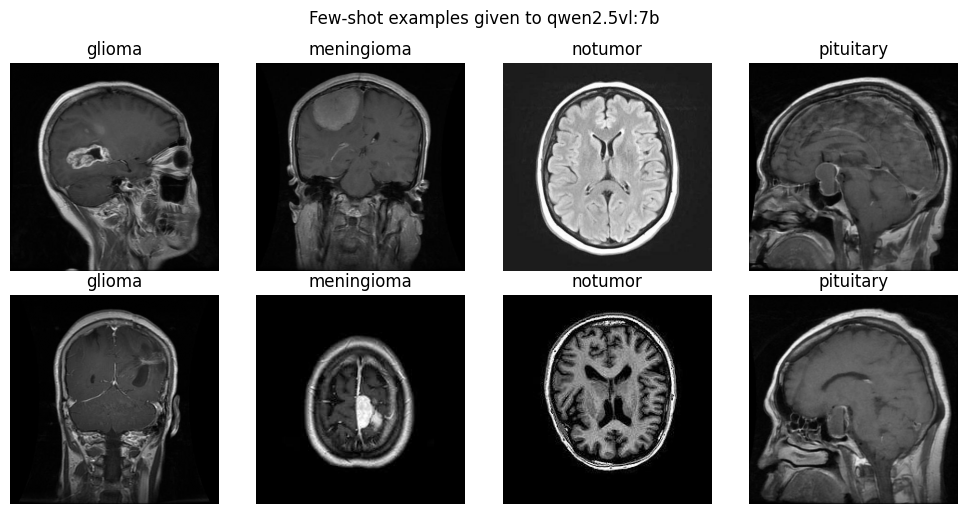

In [11]:
few_shot_df = (
    train_df.groupby("Labels").sample(n=FEW_SHOT_PER_CLASS, random_state=SEED)
    .sample(frac=1, random_state=SEED)     # shuffle the order of the examples
)

def image_bytes(path):
    return Path(path).read_bytes()

def label_json(label):
    return Prediction(label=label).model_dump_json()     # '{"label":"glioma"}'

# Build the example turns once and reuse them for every request
FEW_SHOT_MESSAGES = []
for _, row in few_shot_df.iterrows():
    FEW_SHOT_MESSAGES += [
        {"role": "user", "content": "Classify this scan.", "images": [image_bytes(row["Path"])]},
        {"role": "assistant", "content": label_json(row["Labels"])},
    ]

fig, axes = plt.subplots(FEW_SHOT_PER_CLASS, len(CLASSES), figsize=(10, 2.6 * FEW_SHOT_PER_CLASS), squeeze=False)
for col, (label, group) in enumerate(few_shot_df.groupby("Labels")):
    for row_i, path in enumerate(group["Path"]):
        axes[row_i, col].imshow(plt.imread(path), cmap="gray")
        axes[row_i, col].set_title(label)
        axes[row_i, col].axis("off")
plt.suptitle(f"Few-shot examples given to {MODEL}")
plt.tight_layout()
plt.show()

## Classifying one image

chat_once sends one image (plus the few-shot examples, if requested) to the model with temperature=0 so the answers are as deterministic as possible. classify_image wraps it and returns the predicted label.

There is no rate limit with a local model, but calls can still fail, for example a timeout while the model loads or an out-of-memory error from the server. In those cases we wait and retry with exponential backoff (2 s, 4 s). If it still fails after max_retries, we return None and the image is counted as an error rather than crashing the whole run.

In [12]:
def build_messages(path, few_shot=False):
    messages = [{"role": "system", "content": PROMPT}]
    if few_shot:
        messages += FEW_SHOT_MESSAGES
    messages.append({"role": "user", "content": "Classify this scan.", "images": [image_bytes(path)]})
    return messages

def chat_once(path, few_shot=False):
    return client.chat(
        model=MODEL,
        messages=build_messages(path, few_shot),
        format=RESPONSE_SCHEMA,
        options={"temperature": 0, "seed": SEED, "num_ctx": NUM_CTX},
    )

def classify_image(path, few_shot=False, max_retries=3):
    for attempt in range(max_retries):
        try:
            response = chat_once(path, few_shot)
            return Prediction.model_validate_json(response.message.content).label.value
        except ollama.ResponseError as e:
            error, retryable = e, e.status_code >= 500
        except (ConnectionError, httpx.TransportError) as e:
            error, retryable = e, True
        except ValueError as e:  # reply could not be parsed into a label
            print(f"Unparseable reply for {path}: {e}")
            return None

        if retryable and attempt < max_retries - 1:
            time.sleep(2 ** (attempt + 1))
        else:
            print(f"Failed on {path}: {error}")
            return None

### Sanity check

Before looping over hundreds of images, we test the function on a single test image to make sure the server, model name and schema all work. It also prints how many prompt tokens each setup uses and how long one call takes, which is useful for two things:

- **Run time**: multiply the seconds per image by the number of images to estimate a full run. The very first call is slower because it loads the model into GPU memory, and the first few-shot call is slower because the example images are processed for the first time.
- **Context window**: the few-shot prompt token count must be below NUM_CTX. If this cell fails with exceeds the available context size, raise NUM_CTX (or lower FEW_SHOT_PER_CLASS) in the configuration cell and re-run from there.

In [13]:
sample = test_df.iloc[0]
print("true label:", sample["Labels"])

for few_shot in (False, True):
    r = chat_once(sample["Path"], few_shot=few_shot)
    label = Prediction.model_validate_json(r.message.content).label.value
    secs = (r.total_duration or 0) / 1e9
    name = "few-shot " if few_shot else "zero-shot"
    print(f"{name}: {label:<10} prompt tokens = {r.prompt_eval_count}, time = {secs:.1f}s")

print(f"context window (NUM_CTX) = {NUM_CTX} tokens")

true label: glioma
zero-shot: notumor    prompt tokens = 1201, time = 126.6s
few-shot : notumor    prompt tokens = 9648, time = 22.1s
context window (NUM_CTX) = 12288 tokens


## Classifying the test set

classify_dataset goes through every image in a dataframe and records the model's prediction.

Because a full run takes a while, each successful prediction is **appended to a CSV after every image**, in this run's folder inside data/vlm_results/ (git-ignored, see the configuration section). If the run is interrupted (closed laptop, Ollama restarted), simply re-run the cell: images that already have a prediction are skipped and it picks up where it left off. Images where the call failed are not saved, so a re-run retries them.

The file name contains the model name, so each model gets its own results. The cache is **not** keyed on the prompt, NUM_CTX, FEW_SHOT_PER_CLASS or SEED: if you change one of those, delete the CSV to start from scratch.

In [14]:
def cache_file(mode, results_dir=None):
    safe_model = re.sub(r"[^A-Za-z0-9._-]", "_", MODEL)   # ':' in 'qwen2.5vl:3b' is not allowed in Windows file names
    return (results_dir or RESULTS_DIR) / f"ollama_{safe_model}_{mode}.csv"

def classify_dataset(df, few_shot=False):
    mode = "few_shot" if few_shot else "zero_shot"
    path = cache_file(mode)

    done = {}
    if path.exists() and path.stat().st_size > 0:
        cached = pd.read_csv(path)
        done = dict(zip(cached["Path"], cached["Prediction"]))
    write_header = not path.exists() or path.stat().st_size == 0

    rows = []
    start = time.time()
    with open(path, "a", newline="") as f:
        writer = csv.writer(f)
        if write_header:
            writer.writerow(["Path", "Prediction"])
            f.flush()

        for i, row in enumerate(df.itertuples(), start=1):
            pred = done.get(row.Path)
            if pred is None:
                pred = classify_image(row.Path, few_shot=few_shot)
                if pred is not None:          # failures are not cached, so a re-run tries them again
                    writer.writerow([row.Path, pred])
                    f.flush()
                    done[row.Path] = pred
            rows.append({"Path": row.Path, "Labels": row.Labels, "Prediction": pred})

            if i % 25 == 0 or i == len(df):
                print(f"[{mode}] {i}/{len(df)} images ({time.time() - start:.0f}s)")

    return pd.DataFrame(rows)

### Zero-shot run

In [15]:
zero_shot_results = classify_dataset(test_df, few_shot=False)
zero_shot_results.head()

[zero_shot] 25/1584 images (63s)
[zero_shot] 50/1584 images (128s)
[zero_shot] 75/1584 images (194s)
[zero_shot] 100/1584 images (260s)
[zero_shot] 125/1584 images (324s)
[zero_shot] 150/1584 images (389s)
[zero_shot] 175/1584 images (454s)
[zero_shot] 200/1584 images (520s)
[zero_shot] 225/1584 images (585s)
[zero_shot] 250/1584 images (651s)
[zero_shot] 275/1584 images (716s)
[zero_shot] 300/1584 images (780s)
[zero_shot] 325/1584 images (845s)
[zero_shot] 350/1584 images (910s)
[zero_shot] 375/1584 images (976s)
[zero_shot] 400/1584 images (1042s)
[zero_shot] 425/1584 images (1106s)
[zero_shot] 450/1584 images (1171s)
[zero_shot] 475/1584 images (1235s)
[zero_shot] 500/1584 images (1303s)
[zero_shot] 525/1584 images (1369s)
[zero_shot] 550/1584 images (1435s)
[zero_shot] 575/1584 images (1502s)
[zero_shot] 600/1584 images (1570s)
[zero_shot] 625/1584 images (1637s)
[zero_shot] 650/1584 images (1704s)
[zero_shot] 675/1584 images (1770s)
[zero_shot] 700/1584 images (1838s)
[zero_shot]

,Path,Labels,Prediction
0,/content/drive/MyDrive/Colab Notebooks/Testing...,glioma,notumor
1,/content/drive/MyDrive/Colab Notebooks/Testing...,glioma,notumor
2,/content/drive/MyDrive/Colab Notebooks/Testing...,glioma,notumor
3,/content/drive/MyDrive/Colab Notebooks/Testing...,glioma,pituitary
4,/content/drive/MyDrive/Colab Notebooks/Testing...,glioma,pituitary


### Few-shot run

In [16]:
few_shot_results = classify_dataset(test_df, few_shot=True)
few_shot_results.head()

[few_shot] 25/1584 images (79s)
[few_shot] 50/1584 images (142s)
[few_shot] 75/1584 images (206s)
[few_shot] 100/1584 images (270s)
[few_shot] 125/1584 images (333s)
[few_shot] 150/1584 images (396s)
[few_shot] 175/1584 images (459s)
[few_shot] 200/1584 images (522s)
[few_shot] 225/1584 images (585s)
[few_shot] 250/1584 images (649s)
[few_shot] 275/1584 images (713s)
[few_shot] 300/1584 images (775s)
[few_shot] 325/1584 images (838s)
[few_shot] 350/1584 images (901s)
[few_shot] 375/1584 images (965s)
[few_shot] 400/1584 images (1029s)
[few_shot] 425/1584 images (1092s)
[few_shot] 450/1584 images (1155s)
[few_shot] 475/1584 images (1218s)
[few_shot] 500/1584 images (1282s)
[few_shot] 525/1584 images (1346s)
[few_shot] 550/1584 images (1410s)
[few_shot] 575/1584 images (1476s)
[few_shot] 600/1584 images (1541s)
[few_shot] 625/1584 images (1606s)
[few_shot] 650/1584 images (1672s)
[few_shot] 675/1584 images (1737s)
[few_shot] 700/1584 images (1804s)
[few_shot] 725/1584 images (1869s)
[few

,Path,Labels,Prediction
0,/content/drive/MyDrive/Colab Notebooks/Testing...,glioma,notumor
1,/content/drive/MyDrive/Colab Notebooks/Testing...,glioma,notumor
2,/content/drive/MyDrive/Colab Notebooks/Testing...,glioma,notumor
3,/content/drive/MyDrive/Colab Notebooks/Testing...,glioma,pituitary
4,/content/drive/MyDrive/Colab Notebooks/Testing...,glioma,notumor


## Evaluation

We use the same metrics as the other notebooks: accuracy, macro F1 and a per-class report. Any image where the call failed (None) is counted as **wrong**, so failures cannot inflate the score.

The confusion matrix shows *which* classes the model mixes up, which is more informative than the overall score alone. We also count the most serious error, the same one Decision_Tree_Baseline.ipynb highlights: a scan with a tumour that the model calls notumor.

===== Zero-shot =====
failed calls: 0/1584
tumour scans predicted as 'notumor': 267/1184
              precision    recall  f1-score   support

      glioma       0.35      0.07      0.11       386
  meningioma       0.00      0.00      0.00       398
     notumor       0.59      0.97      0.73       400
   pituitary       0.43      0.91      0.58       400

    accuracy                           0.49      1584
   macro avg       0.34      0.49      0.36      1584
weighted avg       0.34      0.49      0.36      1584



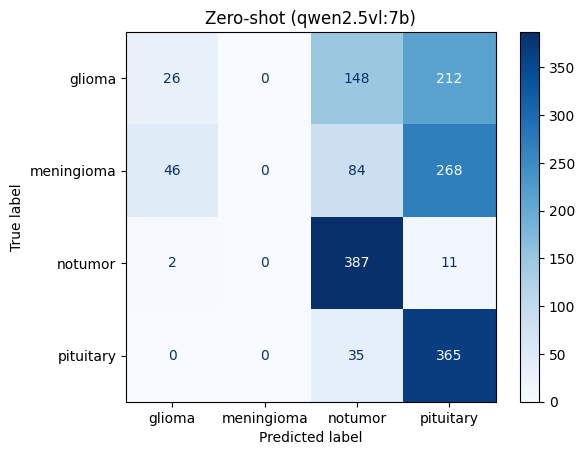

===== Few-shot =====
failed calls: 0/1584
tumour scans predicted as 'notumor': 379/1184
              precision    recall  f1-score   support

      glioma       0.38      0.07      0.12       386
  meningioma       0.74      0.06      0.12       398
     notumor       0.51      1.00      0.68       400
   pituitary       0.44      0.77      0.56       400

    accuracy                           0.48      1584
   macro avg       0.52      0.48      0.37      1584
weighted avg       0.52      0.48      0.37      1584



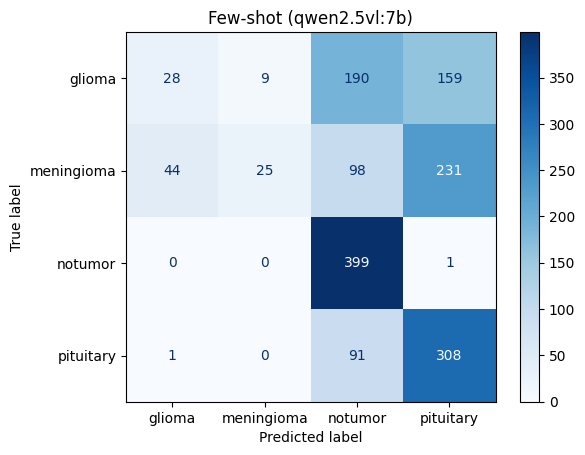

In [17]:
def evaluate(results, title):
    n_failed = int(results["Prediction"].isna().sum())
    y_true = results["Labels"]
    y_pred = results["Prediction"].fillna("failed")

    has_tumour = y_true != "notumor"
    missed = int((has_tumour & (y_pred == "notumor")).sum())

    print(f"===== {title} =====")
    print(f"failed calls: {n_failed}/{len(results)}")
    print(f"tumour scans predicted as 'notumor': {missed}/{int(has_tumour.sum())}")
    print(classification_report(y_true, y_pred, labels=CLASSES, zero_division=0))

    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=CLASSES, cmap="Blues")
    plt.title(f"{title} ({MODEL})")
    plt.show()

    return {
        "setup": title,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, labels=CLASSES, average="macro", zero_division=0),
        "missed_tumours": missed,
        "failed": n_failed,
    }

summary = [
    evaluate(zero_shot_results, "Zero-shot"),
    evaluate(few_shot_results, "Few-shot"),
]

## Summary

Side-by-side comparison of both setups against the naive (stratified random) baseline from Naive_Benchmark.ipynb, which scored ≈ 0.25 macro F1.

In [18]:
summary_df = pd.DataFrame(summary + [{"setup": "Naive baseline", "accuracy": 0.25, "macro_f1": 0.25, "missed_tumours": None, "failed": 0}])
print(f"Model: {MODEL}, test images: {len(test_df)}")
summary_df.round(3)

Model: qwen2.5vl:7b, test images: 1584


,setup,accuracy,macro_f1,missed_tumours,failed
0,Zero-shot,0.491,0.357,267.0,0
1,Few-shot,0.480,0.369,379.0,0
2,Naive baseline,0.250,0.250,NaN,0


## Full test set vs the 200-image pilot

We first ran a pilot on 200 images (50 per class) and drew conclusions from it. Here we check whether those conclusions hold on the **full test set** of 1,584 images. The pilot's predictions are read back from data/vlm_results/200 Test Images/.

For each setup the table shows the same metrics for the pilot run and the full run:

- accuracy_95ci is the **margin of error** on accuracy (the ± of a 95% confidence interval, using the normal approximation 1.96 × √(p(1−p)/n)). With 200 images it is about ±0.07, with 1,584 about ±0.025. If the full-run accuracy lies within the pilot's margin, the pilot was a fair estimate.
- missed_tumour_rate is the fraction of tumour scans predicted as notumor. It is a rate rather than a count because the two sets have different sizes.
- f1_<class> is the per-class F1, and the second table shows how often the model gives each answer. Together they show whether the class-level findings (no meningioma predictions zero-shot, the notumor bias few-shot) still hold.

The 200 pilot images are also part of the full test set, so the full run classified them a second time. With temperature=0 and a fixed seed the answers should be (almost) identical. The **agreement** line checks this, which tells us whether the results are reproducible.

This section only runs when SAMPLE_PER_CLASS = None.

In [2]:
import re
from pathlib import Path
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score
from google.colab import drive

drive.mount('/content/drive')

RESULTS_ROOT = Path("/content/drive/MyDrive/Colab Notebooks/vlm_results")
FULL_DIR = RESULTS_ROOT / "Full Test set"
CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]

OLD_MODEL = "qwen2.5vl:3b"
NEW_MODEL = "qwen2.5vl:7b"

def path_key(p):
    return "/".join(Path(str(p).replace("\\", "/")).parts[-2:])   # e.g. "glioma/Te-gl_1.jpg"

def load_preds(model, mode):
    safe = re.sub(r"[^A-Za-z0-9._-]", "_", model)
    df = pd.read_csv(FULL_DIR / f"ollama_{safe}_{mode}.csv")
    df["key"] = df["Path"].map(path_key)
    df["Labels"] = df["key"].str.split("/").str[0]                # true label from the class folder
    return df[["key", "Labels", "Prediction"]]

def scores(y_true, y_pred):
    has_tumour = y_true != "notumor"
    acc = accuracy_score(y_true, y_pred)
    return {
        "n": len(y_true),
        "accuracy": acc,
        "accuracy_95ci": 1.96 * (acc * (1 - acc) / len(y_true)) ** 0.5,
        "macro_f1": f1_score(y_true, y_pred, labels=CLASSES, average="macro", zero_division=0),
        "missed_tumour_rate": (has_tumour & (y_pred == "notumor")).sum() / has_tumour.sum(),
        **{f"f1_{c}": f for c, f in zip(CLASSES, f1_score(y_true, y_pred, labels=CLASSES, average=None, zero_division=0))},
    }

rows, shares = [], {}
for title, mode in [("Zero-shot", "zero_shot"), ("Few-shot", "few_shot")]:
    old = load_preds(OLD_MODEL, mode)
    new = load_preds(NEW_MODEL, mode)
    both = old.merge(new, on="key", suffixes=("_old", "_new"))
    both["Labels"] = both["Labels_old"]
    print(f"{title}: comparing on {len(both)} images (old file {len(old)}, new file {len(new)})")

    for name, col in [(OLD_MODEL, "Prediction_old"), (NEW_MODEL, "Prediction_new")]:
        y_pred = both[col].fillna("failed")
        rows.append({"setup": title, "model": name, **scores(both["Labels"], y_pred)})
        shares[(title, name)] = both[col].value_counts(normalize=True).reindex(CLASSES, fill_value=0)

    old_ok = (both["Prediction_old"] == both["Labels"]).to_numpy()
    new_ok = (both["Prediction_new"] == both["Labels"]).to_numpy()
    print(f"  both correct {(old_ok & new_ok).sum()}, only {NEW_MODEL} correct {(~old_ok & new_ok).sum()}, "
          f"only {OLD_MODEL} correct {(old_ok & ~new_ok).sum()}, both wrong {(~old_ok & ~new_ok).sum()}")

display(pd.DataFrame(rows).set_index(["setup", "model"]).round(3))
print("Share of predictions per class (true share is ~0.25 each):")
display(pd.DataFrame(shares).round(3))

Mounted at /content/drive
Zero-shot: comparing on 1584 images (old file 1584, new file 1584)
  both correct 395, only qwen2.5vl:7b correct 383, only qwen2.5vl:3b correct 279, both wrong 527
Few-shot: comparing on 1584 images (old file 1584, new file 1584)
  both correct 448, only qwen2.5vl:7b correct 312, only qwen2.5vl:3b correct 180, both wrong 644


n  accuracy  accuracy_95ci  macro_f1  \
setup     model                                                   
Zero-shot qwen2.5vl:3b  1584     0.426          0.024     0.371   
          qwen2.5vl:7b  1584     0.491          0.025     0.357   
Few-shot  qwen2.5vl:3b  1584     0.396          0.024     0.341   
          qwen2.5vl:7b  1584     0.480          0.025     0.369   

                        missed_tumour_rate  f1_glioma  f1_meningioma  \
setup     model                                                        
Zero-shot qwen2.5vl:3b               0.123      0.449          0.000   
          qwen2.5vl:7b               0.226      0.113          0.000   
Few-shot  qwen2.5vl:3b               0.541      0.310          0.329   
          qwen2.5vl:7b               0.320      0.122          0.116   

                        f1_notumor  f1_pituitary  
setup     model                                   
Zero-shot qwen2.5vl:3b       0.479         0.557  
          qwen2.5vl:7b       0.734         0.581  
Few-shot  qwen2.5vl:3b       0.535         0.189  
          qwen2.5vl:7b       0.677         0.561

Share of predictions per class (true share is ~0.25 each):


Zero-shot                  Few-shot             
           qwen2.5vl:3b qwen2.5vl:7b qwen2.5vl:3b qwen2.5vl:7b
glioma            0.569        0.047        0.155        0.046
meningioma        0.000        0.000        0.152        0.021
notumor           0.201        0.413        0.645        0.491
pituitary         0.230        0.540        0.048        0.441

## Conclusions

Results for qwen2.5vl:3b on the **full test set of 1,584 images** (1,184 of them with a tumour), with FEW_SHOT_PER_CLASS = 2 and NUM_CTX = 12288. If you re-run with different settings, update this section.

| Setup | Accuracy | Macro F1 | Tumour scans predicted notumor |
|---|---|---|---|
| Zero-shot | 0.426 | 0.371 | 146 / 1,184 (12%) |
| Few-shot | 0.396 | 0.341 | 641 / 1,184 (54%) |
| Naive baseline (Naive_Benchmark.ipynb) | 0.25 | 0.25 | – |
| Decision tree (Decision_Tree_Baseline.ipynb) | 0.77 | 0.77 | – |

**1. The VLM beats random guessing but is far behind a trained model.** Zero-shot macro F1 is 0.37, against 0.25 for the naive baseline and 0.77 for the decision tree. A general-purpose 3B model that has never been trained on our data cannot match even a simple classifier that has.

**2. Zero-shot is heavily biased towards "glioma" and never says "meningioma".** The model predicted glioma for 901 of the 1,584 scans (57%) and never predicted meningioma at all, so meningioma scores 0.00 on every metric. The 398 meningioma scans were labelled glioma (275), pituitary (93) or notumor (30). Healthy scans were called glioma more often than healthy: 225 of 400, against 172 correct. This explains glioma's high recall (0.75) but low precision (0.32). Pituitary (213 of 400 correct, F1 0.56) is the tumour type it recognises best. On the positive side, zero-shot rarely calls a tumour scan healthy (146 of 1,184, 12%).

**3. Few-shot examples made the model worse, not better.** Showing 8 labelled training images lowered macro F1 from 0.37 to 0.34. The model now does predict meningioma (105 of 398 correct), but its bias moved from glioma to notumor, which it predicted for 1,021 of the 1,584 scans (64%). It finds 380 of the 400 healthy scans (recall 0.95) only because it calls almost everything healthy. It labelled 641 of the 1,184 tumour scans as healthy, including 278 of the 400 pituitary scans, so pituitary recall fell from 0.53 to 0.11. Rather than learning what each class looks like, the small model appears to be overwhelmed by 9 images in one prompt and falls back on the "no tumour" answer.

**4. The few-shot setup makes the most serious error.** Calling a tumour scan healthy is the costliest mistake in practice. The few-shot setup does it for more than half of all tumour scans (54%), which on its own rules it out as a useful classifier.

**5. The 200-image pilot was a fair preview.** For both setups, the full-test-set accuracy fell within the pilot's margin of error (zero-shot 0.470 → 0.426, few-shot 0.395 → 0.396). Every pattern above was already visible in the pilot: no meningioma predictions zero-shot, and the notumor bias with examples. The pilot was slightly optimistic for zero-shot (macro F1 0.41 against 0.37).

**Caveats**

- **Uncertainty:** with 1,584 images, accuracy is accurate to about ±2.5 percentage points (95% confidence interval), so differences of a few points between setups should be read with care.
- **Not perfectly reproducible:** the full run classified the 200 pilot images a second time, and despite temperature=0 and a fixed seed it gave the same answer for only 92% (zero-shot) and 94% (few-shot) of them. The most likely cause is small numerical differences between runs when the model is split between CPU and GPU, which flip borderline cases. Individual answers can change from run to run, but the overall scores and biases stayed the same.
- **Different inputs:** the VLM sees the original JPEGs (resized by Ollama), while the classical models see 224x224 or 64x64 grayscale arrays.
- **Small model on limited hardware:** this is a 3B model that ran partly on the CPU of a 4 GB GPU. Larger VLMs may do better, so this result describes a small local VLM, not VLMs in general.
- **No training:** the model's weights are never updated. The training set is only used to pick the 8 few-shot example images shown in the prompt.
- **Not a medical tool:** general-purpose VLMs are not trained or validated for medical diagnosis.